# TRUSTSR Lab 01.1 — Missing Dependency Edge Failure Test

**Project:** TRUSTSR — Trust-Aware Causal Semantic Recovery for Long-Horizon Agentic Systems  
**Status:** Synthetic simulation / research prototype  
**Version:** 0.1.0

## Objective

Test how removing a dependency edge from a declared Causal State Graph (CSG) affects reachability-based contamination analysis.

This lab extends Lab 01's synthetic graph. It does not detect real poisoning, infer real causal edges, or validate production security.

## Research question

If a state is genuinely downstream of a poison source in the synthetic ground-truth graph, but a dependency edge is missing from the graph used by the analyzer, how many affected states will the analyzer fail to flag?

## Definitions

- **Ground-truth graph:** The full synthetic dependency graph defined for this experiment.
- **Observed graph:** The graph available to the analyzer; it may have one edge removed.
- **Expected affected state:** A descendant of the declared poison source in the ground-truth graph.
- **False negative (FN):** An expected affected state not flagged by the observed-graph analysis.
- **False-negative rate (FNR):** `FN / number of expected affected descendants`, when the denominator is non-zero.

All results are generated from an intentionally constructed synthetic scenario. Do not interpret them as empirical results from a real agent.

## 1. Environment setup

In [1]:
%pip -q install networkx pandas matplotlib

In [2]:
import sys
import platform
from datetime import datetime, timezone

import networkx as nx
import pandas as pd
import matplotlib.pyplot as plt

print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("NetworkX:", nx.__version__)
print("Pandas:", pd.__version__)
print("Execution timestamp (UTC):", datetime.now(timezone.utc).isoformat())

Python: 3.12.3
Platform: Linux-6.18.44-fc-v114-x86_64-with-glibc2.39
NetworkX: 3.6.1
Pandas: 3.0.2
Execution timestamp (UTC): 2026-10-11T10:26:24.721288+00:00


## 2. Define the ground-truth graph

The state and edge definitions intentionally match Lab 01. Edge direction is `source → dependent state`.

In [3]:
states = [
    {"id": "M1", "label": "Trusted project requirement", "kind": "memory", "status": "trusted"},
    {"id": "M2", "label": "Poisoned memory: unsafe instruction", "kind": "memory", "status": "poisoned"},
    {"id": "D1", "label": "Planning decision A", "kind": "decision", "status": "normal"},
    {"id": "D2", "label": "Planning decision B", "kind": "decision", "status": "normal"},
    {"id": "P1", "label": "Execution plan A", "kind": "plan", "status": "normal"},
    {"id": "P2", "label": "Execution plan B", "kind": "plan", "status": "normal"},
    {"id": "A1", "label": "Derived action record", "kind": "action", "status": "normal"},
    {"id": "S1", "label": "Independent status note", "kind": "state", "status": "normal"},
]
dependencies = [
    ("M1", "D1"),
    ("M2", "D1"),
    ("D1", "P1"),
    ("P1", "A1"),
    ("M2", "D2"),
    ("D2", "P2"),
    ("M1", "S1"),
]
POISON_SOURCE = "M2"

G_truth = nx.DiGraph()
for state in states:
    G_truth.add_node(state["id"], **state)
G_truth.add_edges_from(dependencies)

assert nx.is_directed_acyclic_graph(G_truth)
expected_affected = nx.descendants(G_truth, POISON_SOURCE)

print("Ground-truth nodes:", G_truth.number_of_nodes())
print("Ground-truth edges:", G_truth.number_of_edges())
print("Expected affected descendants:", sorted(expected_affected))
print("Expected affected count:", len(expected_affected))

Ground-truth nodes: 8
Ground-truth edges: 7
Expected affected descendants: ['A1', 'D1', 'D2', 'P1', 'P2']
Expected affected count: 5


## 3. Establish baseline analysis

The baseline analyzer receives the complete graph. This gives a reference point for comparison with a graph containing a missing edge.

In [4]:
def analyze_reachability(graph: nx.DiGraph, source: str) -> set[str]:
    if source not in graph:
        raise KeyError(f"Source node {source!r} is absent from graph")
    return set(nx.descendants(graph, source))

baseline_flagged = analyze_reachability(G_truth, POISON_SOURCE)
baseline_false_negatives = expected_affected - baseline_flagged

print("Baseline flagged:", sorted(baseline_flagged))
print("Baseline false negatives:", sorted(baseline_false_negatives))
print("Baseline FNR:", len(baseline_false_negatives) / len(expected_affected) if expected_affected else float("nan"))

assert baseline_flagged == expected_affected
assert baseline_false_negatives == set()

Baseline flagged: ['A1', 'D1', 'D2', 'P1', 'P2']
Baseline false negatives: []
Baseline FNR: 0.0


## 4. Simulate one missing dependency edge

We remove `D1 → P1` from the observed graph. In the ground-truth scenario, P1 and A1 remain downstream of the poison source through `M2 → D1 → P1 → A1`; however, the analyzer can no longer traverse from D1 to P1 in the observed graph.

This is a controlled fault injection, not an estimate of how often real provenance systems omit edges.

In [5]:
MISSING_EDGE = ("D1", "P1")

G_observed = G_truth.copy()
if not G_observed.has_edge(*MISSING_EDGE):
    raise ValueError(f"Cannot remove absent edge: {MISSING_EDGE}")
G_observed.remove_edge(*MISSING_EDGE)

observed_flagged = analyze_reachability(G_observed, POISON_SOURCE)
false_negatives = expected_affected - observed_flagged
false_positives = observed_flagged - expected_affected

fnr = len(false_negatives) / len(expected_affected) if expected_affected else float("nan")
recall = len(observed_flagged & expected_affected) / len(expected_affected) if expected_affected else float("nan")

print("Removed edge:", MISSING_EDGE)
print("Expected affected:", sorted(expected_affected))
print("Observed flagged:", sorted(observed_flagged))
print("False negatives:", sorted(false_negatives))
print("False positives:", sorted(false_positives))
print(f"False-negative rate: {fnr:.1%}")
print(f"Recall: {recall:.1%}")

Removed edge: ('D1', 'P1')
Expected affected: ['A1', 'D1', 'D2', 'P1', 'P2']
Observed flagged: ['D1', 'D2', 'P2']
False negatives: ['A1', 'P1']
False positives: []
False-negative rate: 40.0%
Recall: 60.0%


## 5. Build a state-level comparison table

In [6]:
state_report = pd.DataFrame(states)[["id", "label", "kind"]]
state_report["expected_affected"] = state_report["id"].isin(expected_affected)
state_report["baseline_flagged"] = state_report["id"].isin(baseline_flagged)
state_report["observed_flagged_after_edge_removal"] = state_report["id"].isin(observed_flagged)
state_report["false_negative"] = state_report["expected_affected"] & ~state_report["observed_flagged_after_edge_removal"]
state_report["false_positive"] = ~state_report["expected_affected"] & state_report["observed_flagged_after_edge_removal"]

display(state_report)

summary = pd.DataFrame([
    {
        "scenario": "Complete graph (baseline)",
        "expected_affected_descendants": len(expected_affected),
        "flagged_descendants": len(baseline_flagged & expected_affected),
        "false_negatives": len(expected_affected - baseline_flagged),
        "false_negative_rate": (len(expected_affected - baseline_flagged) / len(expected_affected)) if expected_affected else float("nan"),
        "false_positives": len(baseline_flagged - expected_affected),
    },
    {
        "scenario": f"Missing edge {MISSING_EDGE[0]} -> {MISSING_EDGE[1]}",
        "expected_affected_descendants": len(expected_affected),
        "flagged_descendants": len(observed_flagged & expected_affected),
        "false_negatives": len(expected_affected - observed_flagged),
        "false_negative_rate": (len(expected_affected - observed_flagged) / len(expected_affected)) if expected_affected else float("nan"),
        "false_positives": len(observed_flagged - expected_affected),
    }
])
display(summary)

   id                                label      kind  expected_affected  baseline_flagged  observed_flagged_after_edge_removal  false_negative  false_positive
0  M1          Trusted project requirement    memory              False             False                                False           False           False
1  M2  Poisoned memory: unsafe instruction    memory              False             False                                False           False           False
2  D1                  Planning decision A  decision               True              True                                 True           False           False
3  D2                  Planning decision B  decision               True              True                                 True           False           False
4  P1                     Execution plan A      plan               True              True                                False            True           False
5  P2                     Execution plan B    

                    scenario  expected_affected_descendants  flagged_descendants  false_negatives  false_negative_rate  false_positives
0  Complete graph (baseline)                              5                    5                0                  0.0                0
1      Missing edge D1 -> P1                              5                    3                2                  0.4                0

## 6. Visualize the observed graph after edge removal

Legend: red=poison source; orange=flagged; purple=missed affected state; light blue=not flagged


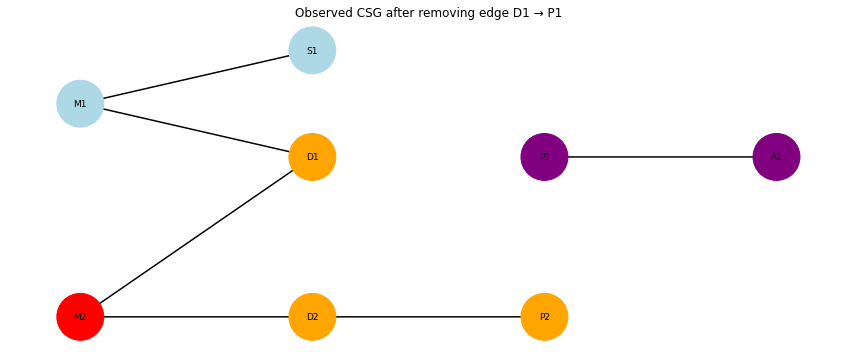

In [7]:
pos = {
    "M1": (0, 2),
    "M2": (0, 0),
    "D1": (1.5, 1.5),
    "D2": (1.5, 0),
    "P1": (3, 1.5),
    "P2": (3, 0),
    "A1": (4.5, 1.5),
    "S1": (1.5, 2.5),
}

node_colors = []
for node in G_observed.nodes():
    if node == POISON_SOURCE:
        node_colors.append("red")
    elif node in false_negatives:
        node_colors.append("purple")  # Expected affected but missed
    elif node in observed_flagged:
        node_colors.append("orange")  # Flagged by observed graph
    else:
        node_colors.append("lightblue")

plt.figure(figsize=(12, 5))
nx.draw_networkx_edges(G_observed, pos, arrows=True, arrowsize=18, width=1.5)
nx.draw_networkx_nodes(G_observed, pos, node_color=node_colors, node_size=2200)
nx.draw_networkx_labels(G_observed, pos, font_size=9)
plt.title(f"Observed CSG after removing edge {MISSING_EDGE[0]} → {MISSING_EDGE[1]}")
plt.axis("off")
plt.tight_layout()
plt.show()

print("Legend: red=poison source; orange=flagged; purple=missed affected state; light blue=not flagged")

## 7. Assertions: verify the failure mode

In [8]:
# Ground truth includes five descendants: D1, D2, P1, P2, A1.
assert expected_affected == {"D1", "D2", "P1", "P2", "A1"}

# Baseline should flag all expected descendants.
assert baseline_flagged == expected_affected
assert baseline_false_negatives == set()

# With D1 -> P1 removed, D1 remains reachable, but P1 and A1 are missed.
assert "D1" in observed_flagged
assert "P1" not in observed_flagged
assert "A1" not in observed_flagged
assert false_negatives == {"P1", "A1"}
assert len(false_negatives) == 2
assert abs(fnr - 0.4) < 1e-12
assert false_positives == set()

print("PASS: complete-graph baseline has zero false negatives.")
print("PASS: missing edge causes P1 and A1 to be missed.")
print("PASS: false-negative rate is 40.0% in this constructed scenario.")
print("All Lab 01.1 assertions passed.")

PASS: complete-graph baseline has zero false negatives.
PASS: missing edge causes P1 and A1 to be missed.
PASS: false-negative rate is 40.0% in this constructed scenario.
All Lab 01.1 assertions passed.


## 8. Export experiment artifacts

In [9]:
state_report.to_csv("trustsr_lab01_1_state_comparison.csv", index=False)
summary.to_csv("trustsr_lab01_1_summary.csv", index=False)

print("Generated files:")
print("- trustsr_lab01_1_state_comparison.csv")
print("- trustsr_lab01_1_summary.csv")

Generated files:
- trustsr_lab01_1_state_comparison.csv
- trustsr_lab01_1_summary.csv


## 9. Interpretation and limitations

### Result for this synthetic scenario

Removing the edge `D1 → P1` makes `P1` and `A1` unreachable from `M2` in the observed graph. Relative to the constructed ground truth, the analyzer misses 2 of 5 expected affected descendants, yielding a synthetic false-negative rate of 40%.

### What this supports

It demonstrates a specific failure mode of reachability-based contamination analysis: **missing dependency edges can cause affected descendants to be missed**.

### What it does not support

- It does not estimate real-world false-negative rates.
- It does not establish how frequently dependency edges are missing in actual agent systems.
- It does not prove that TRUSTSR overall is ineffective or effective.
- It does not measure detection quality for a real poison detector.
- It does not perform recovery.

### Next research step

Test multiple edge-removal patterns and graph sizes, predefine the ground truth, and report all scenarios. Later, test whether conservative handling of unknown dependencies reduces false negatives, while measuring the trade-off in false positives and unnecessary quarantine.

**Reporting rule:** Label all values as results from a synthetic simulation until evaluated against realistic traces or a validated benchmark.